# 03 — Comparación modular de imputadores con ajuste, validación y prueba

El cuaderno 02 divide 2018 cronológicamente en **ajuste (80 %) y validación (20 %)** y reserva 2019 como **prueba externa**. Los hiperparámetros se seleccionan con la validación 2018; la prueba 2019 se consulta después para reportar el desempeño final. No se seleccionan modelos usando la prueba.

Las noches con luz anómala se excluyen antes de generar las máscaras. Este cuaderno vuelve a aplicar la misma regla a los datos, verifica los índices temporales guardados dentro de los `.npz` y no vuelve a recortar las máscaras.

Los predictores se agrupan por familias meteorológicas y relaciones de dominio para reducir redundancia. Los escaladores y modelos se ajustan exclusivamente con el tramo de ajuste. La presión relativa se excluye del conjunto modelado por redundancia con la presión absoluta.

**Importante:** un R² negativo puede ser real: significa que el modelo predice peor que usar la media del valor observado para esas celdas. Agrupar predictores ayuda a controlar redundancia, pero no garantiza R² positivo.


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics.pairwise import nan_euclidean_distances
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

TRAMOS = Path("../data/gold/tramos")
MASCARAS = Path("../data/gold/mascaras")
RESULTADOS_DIR = Path("../data/gold/resultados_modelos")
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
KS = [2, 3, 5, 7, 9, 11, 13, 15, 19]

ARCHIVOS_TRAMOS = {"ajuste_2018": "tramo_ajuste_2018.csv", "prueba_2019": "tramo_evaluacion_2019.csv"}
ARCHIVOS_MASCARAS = {
    "ajuste": ("indice_ajuste_v1.csv", "mascaras_ajuste_v1.npz"),
    "validacion": ("indice_validacion_v1.csv", "mascaras_validacion_v1.npz"),
    "evaluacion": ("indice_evaluacion_v2.csv", "mascaras_evaluacion_v2.npz"),
}
LUZ = "Light(lux)"
NOCHE_INI, NOCHE_FIN = 19, 5
UMBRAL_LUZ_NOCHE = 5.0
PROPORCION_AJUSTE_2018 = 0.80

def es_noche(idx):
    return (idx.hour >= NOCHE_INI) | (idx.hour < NOCHE_FIN)

def filas_noche_anomala(df):
    noche = es_noche(df.index)
    id_noche = df.index.normalize() - pd.to_timedelta((df.index.hour < NOCHE_FIN).astype(int), unit="D")
    malas = pd.Index(id_noche[noche & df[LUZ].gt(UMBRAL_LUZ_NOCHE).fillna(False).to_numpy()]).unique()
    return noche & id_noche.isin(malas)

def limpiar_noches(df):
    return df.loc[~filas_noche_anomala(df)].copy()

raw_2018 = pd.read_csv(TRAMOS / ARCHIVOS_TRAMOS["ajuste_2018"], index_col="Time_dt", parse_dates=["Time_dt", "Time_original"])
raw_2019 = pd.read_csv(TRAMOS / ARCHIVOS_TRAMOS["prueba_2019"], index_col="Time_dt", parse_dates=["Time_dt", "Time_original"])
raw_2018.index = pd.DatetimeIndex(raw_2018.index, name="Time_dt")
raw_2019.index = pd.DatetimeIndex(raw_2019.index, name="Time_dt")
columnas_fuente = [c for c in raw_2018.columns if c != "Time_original"]
if [c for c in raw_2019.columns if c != "Time_original"] != columnas_fuente:
    raise ValueError("Columnas u orden distintos entre los archivos 2018 y 2019")
for nombre, df in [("2018", raw_2018), ("2019", raw_2019)]:
    delta = df.index.to_series().diff().dropna()
    if not (df.index.is_monotonic_increasing and df.index.is_unique and (delta == pd.Timedelta("30min")).all()):
        raise ValueError(f"Índice original irregular en {nombre}; se esperaba frecuencia de 30 minutos")

limpio_2018, limpio_2019 = limpiar_noches(raw_2018), limpiar_noches(raw_2019)
corte = int(np.floor(len(limpio_2018) * PROPORCION_AJUSTE_2018))
if corte < 1 or len(limpio_2018)-corte < 1:
    raise ValueError("No hay suficientes filas 2018 para ajuste/validación")
datos = {
    "ajuste": limpio_2018.iloc[:corte].copy(),
    "validacion": limpio_2018.iloc[corte:].copy(),
    "evaluacion": limpio_2019.copy(),  # prueba externa; conservar clave por compatibilidad
}
variables = [c for c in columnas_fuente if c != "Relative Pressure(hpa)"]
for tramo_id, df in datos.items():
    print(f"{tramo_id:12s} | {df.index.min()} -> {df.index.max()} | filas={len(df):,}")
assert datos["ajuste"].index.max() < datos["validacion"].index.min()
assert datos["validacion"].index.max() < datos["evaluacion"].index.min()


ajuste       | 2018-08-21 06:00:00 -> 2018-09-21 12:30:00 | filas=1,322
validacion   | 2018-09-21 13:00:00 -> 2018-09-30 12:00:00 | filas=331
evaluacion   | 2019-05-01 01:30:00 -> 2019-06-20 08:30:00 | filas=1,855


## 1. Escenarios de faltantes

El cuaderno 02 crea escenarios independientes por tramo, patron y porcentaje. Para cada semilla se usan los mismos ocho campos en todos los tramos y en ambos patrones; `overlap` alinea sus bloques y `disjoint` los sortea por variable.


In [22]:
def cargar_escenarios(tramo_id):
    archivo_indice, archivo_mascara = ARCHIVOS_MASCARAS[tramo_id]
    info = pd.read_csv(MASCARAS / archivo_indice)
    with np.load(MASCARAS / archivo_mascara) as archivo:
        mascaras = archivo["mascaras"]
        columnas = archivo["columnas"].astype(str).tolist()
        if "time_index" not in archivo.files:
            raise ValueError(f"{archivo_mascara} no contiene time_index; vuelve a ejecutar el cuaderno 02 corregido")
        time_index = archivo["time_index"].astype(str)
    df = datos[tramo_id]
    if len(columnas) != len(set(columnas)) or columnas != columnas_fuente:
        raise ValueError(f"Columnas/orden de máscaras no coinciden con datos fuente en {tramo_id}")
    if len(info) != len(mascaras):
        raise ValueError(f"Índice y máscaras tienen distinta cantidad de escenarios en {tramo_id}")
    if mascaras.shape[1] != len(df) or not np.array_equal(time_index, np.asarray(df.index.astype(str), dtype=str)):
        raise ValueError(f"Desalineación temporal en {tramo_id}. Ejecuta primero el cuaderno 02 corregido")
    if info["id"].tolist() != list(range(len(info))):
        raise ValueError(f"IDs de escenarios no consecutivos en {tramo_id}")
    indices_mascara = [columnas.index(c) for c in variables]
    mascaras = mascaras[:, :, indices_mascara]
    return info, mascaras

ESCENARIOS = {tramo_id: cargar_escenarios(tramo_id) for tramo_id in ARCHIVOS_MASCARAS}
for tramo_id, (info, mascaras) in ESCENARIOS.items():
    print(tramo_id, "| escenarios:", len(info), "| forma:", mascaras.shape)


ajuste | escenarios: 1150 | forma: (1150, 1322, 11)
validacion | escenarios: 790 | forma: (790, 331, 11)
evaluacion | escenarios: 1170 | forma: (1170, 1855, 11)


## 2. Esquema de evaluación temporal

Se entrena en la primera parte de 2018 y se eligen hiperparámetros en la parte final de 2018. El tramo 2019 queda como **prueba externa** y no participa en la selección. Aunque el código conserva nombres históricos como `resultados_cv_*` y `resultados_val_*`, los primeros representan la selección sobre el bloque de validación 2018 y los segundos los resultados finales sobre la prueba 2019.


In [23]:
def crear_mapa_predictores(columnas):
    """Reglas de dominio: quitar derivados, duplicados y acumuladores colineales."""
    pos = {nombre: i for i, nombre in enumerate(columnas)}
    temp, humedad = "Outdoor Temperature(°C)", "Outdoor Humidity(%)"
    viento, rafaga = "Wind Speed(km/h)", "Gust(km/h)"
    rocío, sensacion = "DewPoint(°C)", "WindChill(°C)"
    lluvia_h, lluvia_24 = "Hour Rainfall(mm)", "24 Hour Rainfall(mm)"
    acumuladas = [c for c in (lluvia_24, "Week Rainfall(mm)", "Month Rainfall(mm)",
                              "Total Rainfall(mm)") if c in pos]
    derivados = {c for c in (rocío, sensacion) if c in pos}
    mapa = {}
    for objetivo, j in pos.items():
        if objetivo == rocío:
            permitidos = [c for c in (temp, humedad) if c in pos]
        elif objetivo == sensacion:
            permitidos = [c for c in (temp, viento) if c in pos]
        elif objetivo in acumuladas:
            permitidos = [c for c in (lluvia_h, lluvia_24, humedad) if c in pos and c != objetivo]
        else:
            # un solo representante de lluvia (la horaria); los acumulados quedan fuera
            permitidos = [c for c in columnas
                          if c != objetivo and c not in derivados and c not in acumuladas]
            if objetivo not in (viento, rafaga) and rafaga in permitidos:
                permitidos.remove(rafaga)
        mapa[j] = tuple(pos[c] for c in permitidos if c != objetivo)
    return mapa


PREDICTORES_POR_INDICE = crear_mapa_predictores(variables)
PREDICTORES_POR_OBJETIVO = {
    variables[j]: [variables[i] for i in indices]
    for j, indices in PREDICTORES_POR_INDICE.items()
}
display(pd.DataFrame([
    {"objetivo": objetivo, "predictores": ", ".join(predictores)}
    for objetivo, predictores in PREDICTORES_POR_OBJETIVO.items()
]))

# Auditoría: ningún objetivo se usa a sí mismo; la cantidad de predictores queda acotada.
assert all(obj not in preds for obj, preds in PREDICTORES_POR_OBJETIVO.items())
print("Máximo de predictores por objetivo:", max(map(len, PREDICTORES_POR_OBJETIVO.values())))


class KNNPorObjetivo(BaseEstimator, TransformerMixin):
    """KNN por objetivo; comparte distancias para evaluar varios valores de k."""

    def __init__(self, n_neighbors=5, predictor_indices=None):
        self.n_neighbors = n_neighbors
        self.predictor_indices = predictor_indices

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.references_ = {}
        for j in range(self.n_features_in_):
            predictors = tuple((self.predictor_indices or {}).get(j, ()))
            observed = np.isfinite(X[:, j])
            self.references_[j] = (
                predictors,
                X[observed][:, predictors],
                X[observed, j],
                float(np.mean(X[observed, j])) if observed.any() else 0.0,
            )
        return self

    def transform_many_k(self, X, k_values):
        X = np.asarray(X, dtype=float)
        k_values = sorted({int(k) for k in k_values})
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de columnas no coincide con el ajuste de KNN")
        outputs = {k: X.copy() for k in k_values}

        for j, (predictors, ref_x, ref_y, fallback) in self.references_.items():
            rows = np.flatnonzero(np.isnan(X[:, j]))
            if not len(rows):
                continue
            if len(ref_y) and predictors:
                distances = nan_euclidean_distances(X[rows][:, predictors], ref_x)
            else:
                distances = np.full((len(rows), len(ref_y)), np.nan)

            n_take = min(max(k_values), len(ref_y))
            if n_take and distances.shape[1]:
                # Argpartition limita la busqueda a los vecinos que sirven para
                # el mayor k; luego se ordena solo ese bloque reducido.
                candidate_idx = np.argpartition(distances, kth=n_take - 1, axis=1)[:, :n_take]
                candidate_dist = np.take_along_axis(distances, candidate_idx, axis=1)
                order = np.argsort(candidate_dist, axis=1, kind="stable")
                candidate_idx = np.take_along_axis(candidate_idx, order, axis=1)
                candidate_dist = np.take_along_axis(candidate_dist, order, axis=1)
                candidate_y = ref_y[candidate_idx]
            else:
                candidate_dist = np.empty((len(rows), 0))
                candidate_y = np.empty((len(rows), 0))

            for k in k_values:
                use = min(k, n_take)
                if use:
                    valid = np.isfinite(candidate_dist[:, :use])
                    counts = valid.sum(axis=1)
                    totals = np.where(valid, candidate_y[:, :use], 0.0).sum(axis=1)
                    estimates = np.divide(
                        totals, counts, out=np.full(len(rows), fallback, dtype=float), where=counts > 0
                    )
                else:
                    estimates = np.full(len(rows), fallback, dtype=float)
                outputs[k][rows, j] = estimates
        return outputs

    def transform(self, X):
        return self.transform_many_k(X, [self.n_neighbors])[self.n_neighbors]


def matriz(tramo_id):
    return datos[tramo_id][variables].to_numpy(dtype=float)


def rango_de(X):
    rango = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)
    rango[~np.isfinite(rango) | (rango == 0)] = 1.0
    return rango


def puntuar(X_real, mascara, X_imp, rango):
    celdas = mascara & np.isfinite(X_real) & np.isfinite(X_imp)
    columnas_validas = np.where(celdas.any(axis=0))[0]
    r2_columnas = []
    for j in columnas_validas:
        sel = celdas[:, j]
        if sel.sum() >= 2:
            r2_columnas.append(r2_score(X_real[sel, j], X_imp[sel, j]))
    if not celdas.any():
        return np.nan, np.nan
    mse = np.mean((((X_imp - X_real) / rango)[celdas]) ** 2)
    return (np.mean(r2_columnas) if r2_columnas else np.nan), mse


def crear_modelo(nombre):
    baselines = {
        "Media": "mean",
        "Mediana": "median",
        "Moda": "most_frequent",
    }
    if nombre in baselines:
        imputador = SimpleImputer(strategy=baselines[nombre], keep_empty_features=True)
    elif nombre.startswith("KNN k="):
        imputador = KNNPorObjetivo(
            n_neighbors=int(nombre.split("=")[1]),
            predictor_indices=PREDICTORES_POR_INDICE,
        )
    elif nombre == "LinearRegression":
        imputador = RegresionLinealIterativa(
            predictor_indices=PREDICTORES_POR_INDICE,
            max_iter=5,
        )
    elif nombre.startswith("F-KNN "):
        partes = dict(item.split("=") for item in nombre.split()[1:])
        fknn = FocalizedKNNImputer(
            n_neighbors=int(partes["k"]),
            correlation_threshold=float(partes["tau"]),
            n_features=int(partes["n"]),
            lags=FKNN_LAGS,
            max_lags=FKNN_MAX_LAGS,
            predictor_indices=PREDICTORES_POR_INDICE,
        )
        return Pipeline([("fknn", fknn)])
    else:
        # Registrar aqui los constructores de LinearRegression.
        raise ValueError(f"Modelo no registrado: {nombre}")
    return Pipeline([("escalar", MinMaxScaler()), ("imputar", imputador)])


def a_unidades_originales(modelo, X):
    if "fknn" in modelo.named_steps:
        return X
    return modelo.named_steps["escalar"].inverse_transform(X)


def ajustar_modelo(nombre, ids_train):
    X_fit = np.vstack([matriz(t) for t in ids_train])
    modelo = crear_modelo(nombre)
    if nombre.startswith("F-KNN "):
        # Los rezagos se reinician tanto entre tramos como después de noches eliminadas.
        longitudes = []
        for tramo_id in ids_train:
            idx = datos[tramo_id].index
            cortes = np.flatnonzero(idx.to_series().diff().gt(pd.Timedelta("30min")).to_numpy())
            limites = np.r_[0, cortes, len(idx)]
            longitudes.extend(np.diff(limites).astype(int).tolist())
        modelo.fit(X_fit, fknn__segment_lengths=longitudes)
    else:
        modelo.fit(X_fit)
    return modelo, X_fit


def folds_temporales():
    """Selecciona hiperparámetros en la validación cronológica final de 2018.

    La prueba externa 2019 no participa en la selección de modelos.
    """
    return [("validacion_temporal_2018", ["ajuste"], "validacion")]

FOLDS = folds_temporales()
for fold, ids_train, id_valid in FOLDS:
    print(f"fold {fold}: train={ids_train} | validacion={id_valid}")


def evaluar_en_tramo(nombre, ids_train, id_eval, fold=None, semillas=None):
    modelo, X_fit = ajustar_modelo(nombre, ids_train)
    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    if semillas is not None:
        info = info[info["semilla"].isin(semillas)]
    filas = []
    for escenario in info.itertuples(index=False):
        mascara = mascaras[int(escenario.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        X_imp = a_unidades_originales(modelo, modelo.transform(X_oculto))
        r2, mse = puntuar(X_real, mascara, X_imp, rango)
        registro = {
            "tramo_id": id_eval,
            "metodo": nombre,
            "patron": escenario.patron,
            "pct_objetivo": escenario.pct_objetivo,
            "pct_real": 100 * np.count_nonzero(mascara & np.isfinite(X_real)) / np.isfinite(X_real).sum(),
            "n_variables": int(mascara.any(axis=0).sum()),
            "duracion": escenario.duracion,
            "semilla": escenario.semilla,
            "R2": r2,
            "MSE": mse,
        }
        if fold is not None:
            registro["fold"] = fold
        filas.append(registro)
    return pd.DataFrame(filas)


def evaluar_knn_varios_k(ids_train, id_eval, k_values, fold=None):
    """Evalua varios k compartiendo las distancias de cada mascara y objetivo."""
    X_fit = np.vstack([matriz(t) for t in ids_train])
    scaler = MinMaxScaler().fit(X_fit)
    X_fit_scaled = scaler.transform(X_fit)
    imputador = KNNPorObjetivo(
        n_neighbors=max(k_values), predictor_indices=PREDICTORES_POR_INDICE
    ).fit(X_fit_scaled)

    X_real = matriz(id_eval)
    rango = rango_de(X_fit)
    info, mascaras = ESCENARIOS[id_eval]
    filas = []
    total = len(info)
    for numero, escenario in enumerate(info.itertuples(index=False), start=1):
        mascara = mascaras[int(escenario.id)]
        X_oculto = X_real.copy()
        X_oculto[mascara] = np.nan
        predicciones = imputador.transform_many_k(scaler.transform(X_oculto), k_values)
        for k, X_imp_scaled in predicciones.items():
            X_imp = scaler.inverse_transform(X_imp_scaled)
            r2, mse = puntuar(X_real, mascara, X_imp, rango)
            registro = {
                "tramo_id": id_eval,
                "metodo": f"KNN k={k}",
                "patron": escenario.patron,
                "pct_objetivo": escenario.pct_objetivo,
                "pct_real": 100 * np.count_nonzero(mascara & np.isfinite(X_real)) / np.isfinite(X_real).sum(),
                "n_variables": int(mascara.any(axis=0).sum()),
                "duracion": escenario.duracion,
                "semilla": escenario.semilla,
                "R2": r2,
                "MSE": mse,
            }
            if fold is not None:
                registro["fold"] = fold
            filas.append(registro)
        if numero % 10 == 0 or numero == total:
            print(f"KNN {id_eval}: escenario {numero}/{total}")
    return pd.DataFrame(filas)


def guardar_resultados(df, nombre):
    if df is not None and not df.empty:
        df.to_csv(RESULTADOS_DIR / f"{nombre}.csv", index=False)
        print("Guardado:", RESULTADOS_DIR / f"{nombre}.csv", "| filas:", len(df))


COLUMNAS_RESULTADOS = [
    "tramo_id", "metodo", "patron", "pct_objetivo", "pct_real",
    "n_variables", "duracion", "semilla", "R2", "MSE",
]


,objetivo,predictores
0,Indoor Temperature(°C),"Indoor Humidity(%), Outdoor Temperature(°C), O..."
1,Indoor Humidity(%),"Indoor Temperature(°C), Outdoor Temperature(°C..."
2,Outdoor Temperature(°C),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
3,Outdoor Humidity(%),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
4,Absolute Pressure(hpa),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
5,Wind Speed(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
6,Gust(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
7,DewPoint(°C),"Outdoor Temperature(°C), Outdoor Humidity(%)"
8,WindChill(°C),"Outdoor Temperature(°C), Wind Speed(km/h)"
9,Hour Rainfall(mm),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."


Máximo de predictores por objetivo: 8
fold validacion_temporal_2018: train=['ajuste'] | validacion=validacion


## 3. Líneas base: media, mediana y moda

Las líneas base no usan predictores; cada una aprende una estadística por variable exclusivamente con ajuste 2018. Se aplican las mismas máscaras de evaluación 2019 que a los demás métodos, para que la comparación sea equivalente. El R² de la línea base también puede ser negativo y no debe forzarse a positivo.


In [24]:
NOMBRES_BASELINE = ["Media", "Mediana", "Moda"]
partes_cv_baseline = []
for fold, ids_train, id_valid in FOLDS:
    for nombre in NOMBRES_BASELINE:
        partes_cv_baseline.append(evaluar_en_tramo(nombre, ids_train, id_valid, fold=fold))
resultados_cv_baseline = pd.concat(partes_cv_baseline, ignore_index=True)

resultados_val_baseline = pd.concat(
    [evaluar_en_tramo(nombre, ["ajuste"], "evaluacion") for nombre in NOMBRES_BASELINE],
    ignore_index=True,
)
guardar_resultados(resultados_cv_baseline, "baseline_cv")
guardar_resultados(resultados_val_baseline, "baseline_validation")
display(resultados_val_baseline.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/baseline_cv.csv | filas: 2370
Guardado: ../data/gold/resultados_modelos/baseline_validation.csv | filas: 3510


R2     MSE
metodo  patron   pct_objetivo                
Media   disjoint 5            -0.4122  0.0355
                 10           -0.4435  0.0389
                 20           -0.3564  0.0389
                 30           -0.3073  0.0396
                 40           -0.3142  0.0391
                 50           -0.3000  0.0395
        overlap  5            -0.6651  0.0370
                 10           -0.3637  0.0364
                 20           -0.3595  0.0369
                 30           -0.2946  0.0375
                 40           -0.2826  0.0381
                 50           -0.2958  0.0391
Mediana disjoint 5            -0.4162  0.0373
                 10           -0.3998  0.0388
                 20           -0.3291  0.0388
                 30           -0.2970  0.0398
                 40           -0.3010  0.0392
                 50           -0.2835  0.0395
        overlap  5            -0.5798  0.0375
                 10           -0.3369  0.0366
                 20           -0.3366  0.0370
                 30           -0.2899  0.0379
                 40           -0.2743  0.0383
                 50           -0.2872  0.0393
Moda    disjoint 5            -0.7195  0.0495
                 10           -0.7390  0.0526
                 20           -0.7409  0.0568
                 30           -0.7392  0.0585
                 40           -0.6804  0.0549
                 50           -0.6832  0.0561
        overlap  5            -0.7487  0.0492
                 10           -0.6894  0.0502
                 20           -0.6635  0.0507
                 30           -0.6487  0.0520
                 40           -0.6561  0.0535
                 50           -0.7134  0.0569

## 4. KNN: evaluacion de todos los valores de `k`

Se prueban los nueve valores de `k` con todos los escenarios, semillas y patrones en el validación temporal 2018. Para acelerar la busqueda, por cada escenario y variable objetivo se calculan las distancias y se ordenan los vecinos una sola vez hasta el `k` maximo; las predicciones para los demas valores de `k` reutilizan ese orden. El mejor `k` se elige por R² promedio en validación 2018, con MSE como desempate, y se compara en evaluacion 2019.

Cada objetivo usa solo sus predictores permitidos al calcular distancias.


In [25]:
partes_cv_knn = []
for fold, ids_train, id_valid in FOLDS:
    partes_cv_knn.append(evaluar_knn_varios_k(ids_train, id_valid, KS, fold=fold))
resultados_cv_knn = pd.concat(partes_cv_knn, ignore_index=True)
guardar_resultados(resultados_cv_knn, "knn_cv")

tabla_k = (
    resultados_cv_knn
    .assign(k=lambda d: d["metodo"].str.replace("KNN k=", "", regex=False).astype(int))
    .groupby("k")
    .agg(R2_medio=("R2", "mean"), R2_sd=("R2", "std"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .reset_index())
# Selección equilibrada: ranking conjunto de R² (más alto) y MSE normalizado (más bajo).
# Así no se elige k por una sola métrica; el desempate favorece mayor R² y menor MSE.
tabla_k["rango_R2"] = tabla_k["R2_medio"].rank(ascending=False, method="average")
tabla_k["rango_MSE"] = tabla_k["MSE_medio"].rank(ascending=True, method="average")
tabla_k["rango_balanceado"] = (tabla_k["rango_R2"] + tabla_k["rango_MSE"]) / 2
tabla_k = tabla_k.sort_values(["rango_balanceado", "R2_medio", "MSE_medio"], ascending=[True, False, True]).reset_index(drop=True)
display(tabla_k.round(4))

KNN validacion: escenario 10/790
KNN validacion: escenario 20/790
KNN validacion: escenario 30/790
KNN validacion: escenario 40/790
KNN validacion: escenario 50/790
KNN validacion: escenario 60/790
KNN validacion: escenario 70/790
KNN validacion: escenario 80/790
KNN validacion: escenario 90/790
KNN validacion: escenario 100/790
KNN validacion: escenario 110/790
KNN validacion: escenario 120/790
KNN validacion: escenario 130/790
KNN validacion: escenario 140/790
KNN validacion: escenario 150/790
KNN validacion: escenario 160/790
KNN validacion: escenario 170/790
KNN validacion: escenario 180/790
KNN validacion: escenario 190/790
KNN validacion: escenario 200/790
KNN validacion: escenario 210/790
KNN validacion: escenario 220/790
KNN validacion: escenario 230/790
KNN validacion: escenario 240/790
KNN validacion: escenario 250/790
KNN validacion: escenario 260/790
KNN validacion: escenario 270/790
KNN validacion: escenario 280/790
KNN validacion: escenario 290/790
KNN validacion: escenar

,k,R2_medio,R2_sd,MSE_medio,escenarios,rango_R2,rango_MSE,rango_balanceado
0,19,0.0028,2.8246,0.0197,790,1.0,1.0,1.0
1,15,-0.0073,2.8282,0.0199,790,2.0,2.0,2.0
2,13,-0.0169,2.8366,0.0201,790,3.0,3.0,3.0
3,11,-0.0266,2.8348,0.0203,790,4.0,4.0,4.0
4,9,-0.0499,2.8507,0.0208,790,5.0,5.0,5.0
5,7,-0.0609,2.8462,0.0209,790,6.0,6.0,6.0
6,5,-0.1237,2.8859,0.0221,790,7.0,7.0,7.0
7,3,-0.2675,3.1360,0.0240,790,8.0,8.0,8.0
8,2,-0.3647,3.4593,0.0249,790,9.0,9.0,9.0


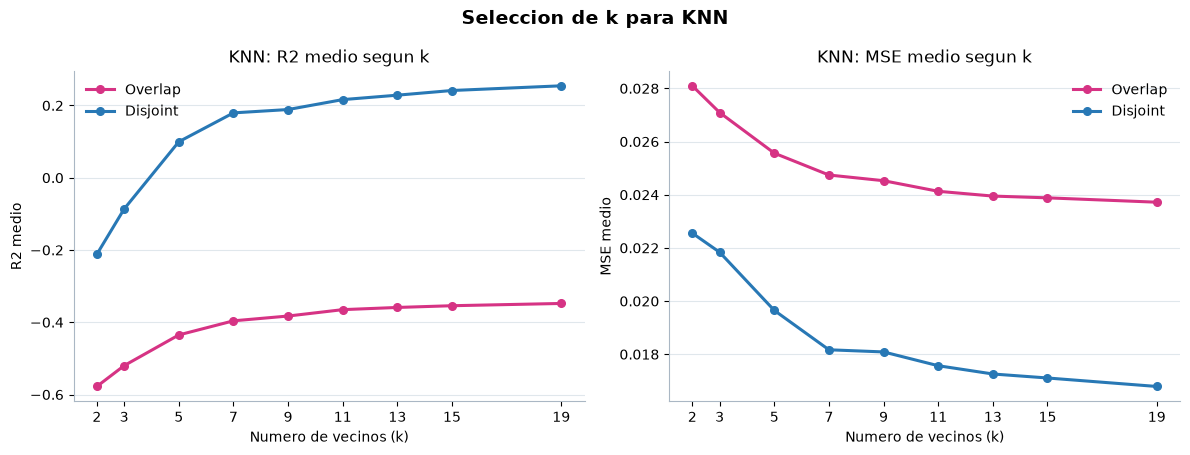

In [26]:
df_knn_grafica = pd.read_csv(RESULTADOS_DIR / "knn_cv.csv")
ks_grafica = sorted(df_knn_grafica["metodo"].str.extract(r"k=(\d+)")[0].dropna().astype(int).unique())
df_knn_grafica["k"] = df_knn_grafica["metodo"].str.extract(r"k=(\d+)")[0].astype(int)
paleta_patrones = {"overlap": "#D63384", "disjoint": "#2878B5"}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, (metrica, etiqueta) in zip(ejes, [("R2", "R2 medio"), ("MSE", "MSE medio")]):
    for patron in ("overlap", "disjoint"):
        curva = (df_knn_grafica[df_knn_grafica["patron"] == patron]
                 .groupby("k")[metrica].mean().reindex(ks_grafica))
        ax.plot(ks_grafica, curva, marker="o", markersize=5.5, linewidth=2.2,
                color=paleta_patrones[patron], label=patron.capitalize())
    ax.set(xlabel="Numero de vecinos (k)", ylabel=etiqueta, title=f"KNN: {etiqueta} segun k")
    ax.set_xticks(ks_grafica)
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8, alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False, loc="best")
fig.suptitle("Seleccion de k para KNN", fontsize=14, fontweight="semibold")
fig.tight_layout()
plt.show()

In [27]:
K_ELEGIDO = int(tabla_k.iloc[0]["k"])
NOMBRE_KNN_ELEGIDO = f"KNN k={K_ELEGIDO}"
K_ELEGIDO_EQ = K_ELEGIDO  # No se fija manualmente: se selecciona solo con validación 2018.
NOMBRE_KNN_ELEGIDO_EQ = f"KNN k={K_ELEGIDO_EQ}"

print("k seleccionado por validación 2018:", K_ELEGIDO)
print("k final para prueba 2019:", K_ELEGIDO_EQ)

resultados_val_knn = evaluar_en_tramo(NOMBRE_KNN_ELEGIDO_EQ, ["ajuste"], "evaluacion")
guardar_resultados(resultados_val_knn, "knn_validation")
display(resultados_val_knn.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))

k seleccionado por validación 2018: 19
k final para prueba 2019: 19


Guardado: ../data/gold/resultados_modelos/knn_validation.csv | filas: 1170


R2     MSE
metodo   patron   pct_objetivo                
KNN k=19 disjoint 5             0.0892  0.0197
                  10            0.0862  0.0222
                  20            0.1475  0.0206
                  30            0.1409  0.0220
                  40            0.0690  0.0249
                  50            0.0358  0.0265
         overlap  5            -0.2463  0.0284
                  10           -0.1131  0.0283
                  20           -0.1423  0.0292
                  30           -0.0814  0.0297
                  40           -0.0954  0.0310
                  50           -0.1202  0.0318

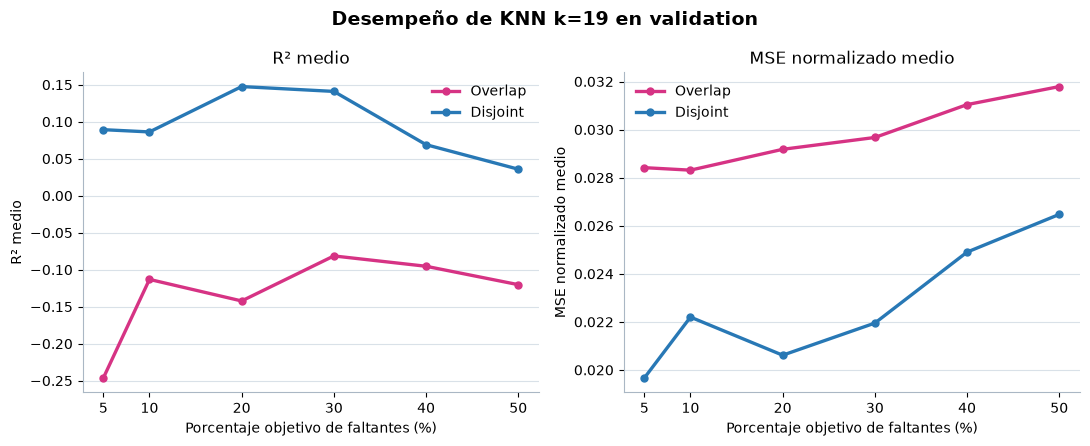

In [28]:
# KNN elegido: desempeño en validation por patrón de faltantes
knn_plot = resultados_val_knn.copy()

colores = {
    "overlap": "#D63384",
    "disjoint": "#2878B5",
}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)

for ax, metrica, etiqueta in zip(
    ejes,
    ["R2", "MSE"],
    ["R² medio", "MSE normalizado medio"],):
    for patron in ["overlap", "disjoint"]:
        sub = knn_plot[knn_plot["patron"] == patron]

        curva = (
            sub.groupby("pct_objetivo")[metrica]
            .mean()
            .sort_index()
        )

        ax.plot(
            curva.index,
            curva.values,
            marker="o",
            linewidth=2.4,
            markersize=5,
            color=colores[patron],
            label=patron.capitalize(),
        )

    ax.set_title(etiqueta)
    ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
    ax.set_xticks(sorted(knn_plot["pct_objetivo"].unique()))
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False)

ejes[0].set_ylabel("R² medio")
ejes[1].set_ylabel("MSE normalizado medio")

fig.suptitle(
    f"Desempeño de {knn_plot['metodo'].iloc[0]} en validation",
    fontsize=14,
    fontweight="semibold",
)
fig.tight_layout()
plt.show()

## 5. Regresion lineal iterativa por objetivo

Se ajusta una regresion lineal independiente para cada columna, respetando `PREDICTORES_POR_OBJETIVO`. Se inicializan los faltantes con medias aprendidas del entrenamiento y se repiten cinco rondas de modelos por objetivo. En cada ronda, las regresiones se ajustan solo con filas donde el objetivo de entrenamiento esta observado; las predicciones actualizan unicamente los faltantes. En la prueba 2019 se aplican los modelos ya ajustados, sin volver a entrenar.

La lista de predictores excluye variables derivadas de otras (`WindChill` y `DewPoint`) y redundancias de viento; sus propias imputaciones se basan en sus variables de origen. La presion relativa queda fuera del conjunto modelado, mientras ambas columnas originales permanecen en los archivos fuente.


In [29]:
from sklearn.linear_model import Ridge

class RegresionLinealIterativa(BaseEstimator, TransformerMixin):
    """Imputacion chained con regresion Ridge, poda por VIF y recorte al rango de train."""

    def __init__(self, predictor_indices=None, max_iter=5, vif_max=10.0, alpha=1.0):
        self.predictor_indices = predictor_indices
        self.max_iter = max_iter
        self.vif_max = vif_max
        self.alpha = alpha

    def _podar_por_vif(self, X, predictors):
        """Poda predictores redundantes; el umbral VIF se calcula por regresión auxiliar."""
        preds = list(dict.fromkeys(predictors))
        while len(preds) > 1:
            Xp = np.asarray(X[:, preds], dtype=float)
            Xp = Xp[np.isfinite(Xp).all(axis=1)]
            if len(Xp) < max(30, len(preds) + 2):
                break
            variabilidad = np.nanstd(Xp, axis=0)
            constantes = variabilidad <= np.finfo(float).eps
            if constantes.any():
                preds = [p for p, constante in zip(preds, constantes) if not constante]
                continue
            corr = np.corrcoef(Xp, rowvar=False)
            # Identifica redundancia extrema incluso cuando la matriz es singular.
            upper = np.triu(np.abs(corr), k=1)
            if upper.size and np.nanmax(upper) >= 0.995:
                a, b = np.unravel_index(np.nanargmax(upper), upper.shape)
                # Conserva el primer predictor de dominio y elimina el redundante.
                preds.pop(b)
                continue
            vif = []
            for k in range(Xp.shape[1]):
                y_aux = Xp[:, k]
                X_aux = np.delete(Xp, k, axis=1)
                r2_aux = LinearRegression().fit(X_aux, y_aux).score(X_aux, y_aux)
                vif.append(1.0 / max(1.0 - min(float(r2_aux), 1.0 - 1e-12), 1e-12))
            if max(vif) <= self.vif_max:
                break
            preds.pop(int(np.argmax(vif)))
        return tuple(preds)

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]
        self.missing_fit_ = np.isnan(X)
        self.initial_values_ = np.nanmean(X, axis=0)
        self.initial_values_[~np.isfinite(self.initial_values_)] = 0.0
        self.min_ = np.nan_to_num(np.nanmin(X, axis=0), nan=-np.inf)
        self.max_ = np.nan_to_num(np.nanmax(X, axis=0), nan=np.inf)
        state = np.where(self.missing_fit_, self.initial_values_[None, :], X)
        self.models_by_iteration_ = []
        self.predictors_ = {
            j: self._podar_por_vif(X, [i for i in (self.predictor_indices or {}).get(j, ()) if i != j])
            for j in range(self.n_features_in_)
        }
        filas_faltantes = [np.flatnonzero(self.missing_fit_[:, j]) for j in range(self.n_features_in_)]
        for _ in range(self.max_iter):
            models = {}
            for j, predictors in self.predictors_.items():
                observed = np.isfinite(X[:, j])
                if not predictors or observed.sum() < 2:
                    continue
                model = Ridge(alpha=self.alpha).fit(state[observed][:, predictors], X[observed, j])
                coef, b = model.coef_.copy(), float(model.intercept_)
                models[j] = (coef, b)   # se guarda como arrays: prediccion manual, mas rapida
                rows = filas_faltantes[j]
                if rows.size:
                    state[rows, j] = np.clip(state[np.ix_(rows, predictors)] @ coef + b,
                                             self.min_[j], self.max_[j])
            self.models_by_iteration_.append(models)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de columnas no coincide con el ajuste")
        missing = np.isnan(X)
        state = np.where(missing, self.initial_values_[None, :], X)
        filas = [np.flatnonzero(missing[:, j]) for j in range(self.n_features_in_)]  # una sola vez
        for models in self.models_by_iteration_:
            for j, (coef, b) in models.items():
                rows = filas[j]
                if rows.size:
                    state[rows, j] = np.clip(state[np.ix_(rows, self.predictors_[j])] @ coef + b,
                                             self.min_[j], self.max_[j])
        return state

NOMBRE_LINEAR = "LinearRegression"
partes_cv_linear = []
for fold, ids_train, id_valid in FOLDS:
    partes_cv_linear.append(evaluar_en_tramo(NOMBRE_LINEAR, ids_train, id_valid, fold=fold))
resultados_cv_linear = pd.concat(partes_cv_linear, ignore_index=True)

resultados_val_linear = evaluar_en_tramo(NOMBRE_LINEAR, ["ajuste"], "evaluacion")
guardar_resultados(resultados_cv_linear, "linear_regression_cv")
guardar_resultados(resultados_val_linear, "linear_regression_validation")
display(resultados_val_linear.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/linear_regression_cv.csv | filas: 790
Guardado: ../data/gold/resultados_modelos/linear_regression_validation.csv | filas: 1170


R2     MSE
metodo           patron   pct_objetivo                
LinearRegression disjoint 5             0.0285  0.0202
                          10            0.0540  0.0227
                          20            0.1591  0.0196
                          30            0.1442  0.0214
                          40            0.0382  0.0258
                          50           -0.0058  0.0279
                 overlap  5            -0.3045  0.0294
                          10           -0.1254  0.0287
                          20           -0.1553  0.0295
                          30           -0.1038  0.0304
                          40           -0.1111  0.0315
                          50           -0.1260  0.0319

In [30]:
modelo_lin, _ = ajustar_modelo("LinearRegression", ["ajuste"])
imp = modelo_lin.named_steps["imputar"]
display(pd.DataFrame({variables[j]: [", ".join(variables[i] for i in p)] for j, p in imp.predictors_.items()}, index=["predictores"]).T)

,predictores
Indoor Temperature(°C),"Indoor Humidity(%), Outdoor Temperature(°C), A..."
Indoor Humidity(%),"Indoor Temperature(°C), Outdoor Humidity(%), A..."
Outdoor Temperature(°C),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Outdoor Humidity(%),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Absolute Pressure(hpa),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Wind Speed(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
Gust(km/h),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."
DewPoint(°C),Outdoor Humidity(%)
WindChill(°C),"Outdoor Temperature(°C), Wind Speed(km/h)"
Hour Rainfall(mm),"Indoor Temperature(°C), Indoor Humidity(%), Ou..."


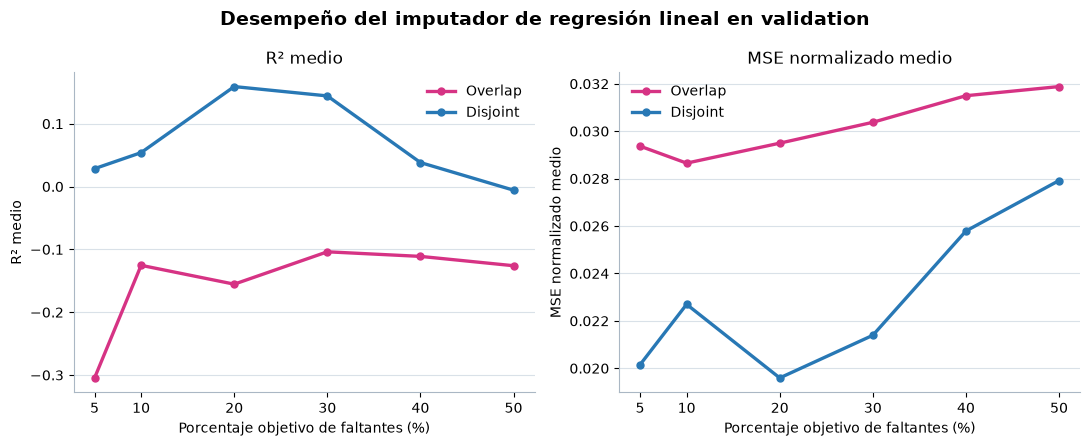

In [31]:
# Regresión lineal: desempeño en validation por patrón de faltantes
linear_plot = resultados_val_linear.copy()

colores = {
    "overlap": "#D63384",
    "disjoint": "#2878B5",}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)

for ax, metrica, etiqueta in zip(
    ejes,
    ["R2", "MSE"],
    ["R² medio", "MSE normalizado medio"],):
    for patron in ["overlap", "disjoint"]:
        sub = linear_plot[linear_plot["patron"] == patron]

        curva = (
            sub.groupby("pct_objetivo")[metrica]
            .mean()
            .sort_index()
        )

        ax.plot(
            curva.index,
            curva.values,
            marker="o",
            linewidth=2.4,
            markersize=5,
            color=colores[patron],
            label=patron.capitalize(),
        )

    ax.set_title(etiqueta)
    ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
    ax.set_xticks(sorted(linear_plot["pct_objetivo"].unique()))
    ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB7C4")
    ax.spines["bottom"].set_color("#AAB7C4")
    ax.legend(frameon=False)

ejes[0].set_ylabel("R² medio")
ejes[1].set_ylabel("MSE normalizado medio")

fig.suptitle(
    "Desempeño del imputador de regresión lineal en validation",
    fontsize=14,
    fontweight="semibold",)
fig.tight_layout()
plt.show()

## 6. F-KNN: busqueda en dos etapas

La exploracion compara 24 configuraciones (`k` = 3, 7, 11, 15; umbral Spearman absoluto = 0.5, 0.6; maximo de variables = 3, 5, 7) con las semillas 1 y 6, manteniendo los dos patrones y los seis porcentajes de faltantes. Se seleccionan las tres mejores por R² promedio en validación (MSE como desempate). Luego esas tres se confirman con las diez semillas en validación 2018. La configuración seleccionada se evalúa una sola vez en la prueba 2019.

La rejilla regularizada es de 30 minutos. Para cada variable, F-KNN selecciona dentro del entrenamiento de cada fold hasta dos rezagos con mayor correlacion absoluta de Spearman entre los candidatos de 1 h, 24 h, 48 h y 168 h (2, 48, 96 y 336 filas). Los rezagos se reinician en los limites de cada tramo; los correlatos tambien se seleccionan solo con entrenamiento y se preservan los valores observados. El articulo usa umbrales sobre correlacion absoluta: [Focalize K-NN](https://link.springer.com/article/10.1007/s10044-024-01262-3).


AVISO: las semillas [1, 6] no existen para validacion; se usaran [201, 202]. Semillas disponibles: [201, 202, 203, 204, 205, 206, 207, 208, 209, 210]
F-KNN exploracion | fold=validacion_temporal_2018 | tramo=validacion | semillas=[201, 202]


Guardado: ../data/gold/resultados_modelos/fknn_cv_exploracion.csv | filas: 3792


,R2_medio,MSE_medio,escenarios
metodo,,,
F-KNN k=15 tau=0.5 n=3,0.0888,0.0180,158
F-KNN k=15 tau=0.5 n=5,0.0877,0.0179,158
F-KNN k=15 tau=0.5 n=7,0.0877,0.0179,158
F-KNN k=11 tau=0.5 n=3,0.0456,0.0183,158
F-KNN k=11 tau=0.5 n=5,0.0453,0.0182,158
F-KNN k=11 tau=0.5 n=7,0.0453,0.0182,158
F-KNN k=15 tau=0.6 n=5,0.0322,0.0190,158
F-KNN k=15 tau=0.6 n=7,0.0322,0.0190,158
F-KNN k=15 tau=0.6 n=3,0.0314,0.0191,158


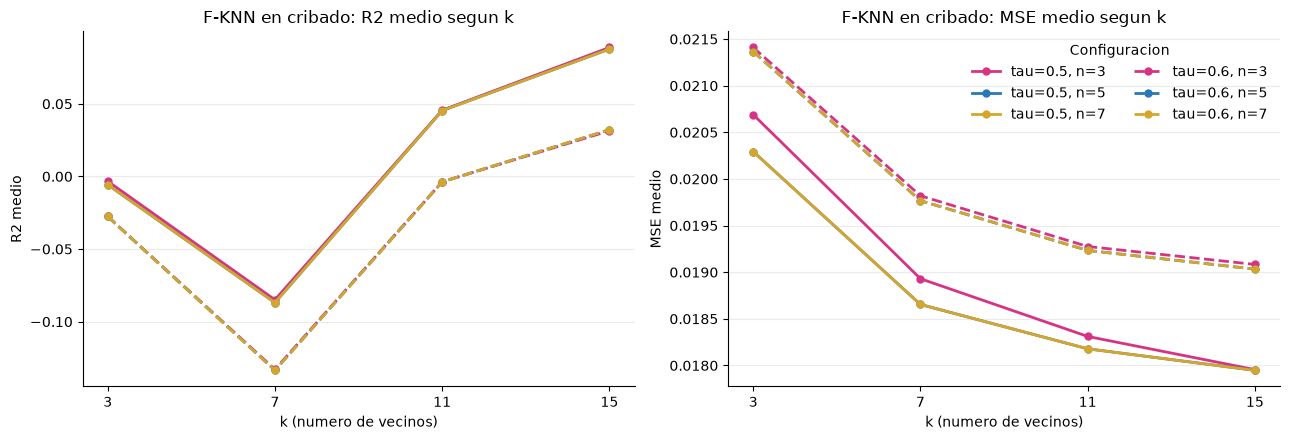

In [32]:
from sklearn.base import BaseEstimator, TransformerMixin

# Tramos de 30 minutos: candidatos de rezago de 1 h, 1 dia, 2 dias y 7 dias.
FKNN_LAGS = [2, 48, 96, 336]
FKNN_MAX_LAGS = 2


class FocalizedKNNImputer(BaseEstimator, TransformerMixin):
    """KNN por variable con correlatos permitidos y rezagos relevantes."""

    def __init__(self, n_neighbors=5, correlation_threshold=0.5, n_features=3,
                 lags=(2, 48, 96, 336), max_lags=2, predictor_indices=None):
        self.n_neighbors = n_neighbors
        self.correlation_threshold = correlation_threshold
        self.n_features = n_features
        self.lags = lags
        self.max_lags = max_lags
        self.predictor_indices = predictor_indices

    @staticmethod
    def _lagged(values, lags):
        n = len(values)
        columns = []
        for lag in lags:
            col = np.full(n, np.nan, dtype=float)
            if lag < n:
                col[lag:] = values[:-lag]
            columns.append(col)
        return np.column_stack(columns) if columns else np.empty((n, 0))

    def fit(self, X, y=None, segment_lengths=None):
        X = np.asarray(X, dtype=float)
        self._fit_reference_ = X.copy()
        self.n_features_in_ = X.shape[1]
        self.scaler_ = MinMaxScaler().fit(X)
        scaled = self.scaler_.transform(X)
        corr = pd.DataFrame(scaled).corr(method="spearman").to_numpy()
        self.selected_ = {}
        self.selected_lags_ = {}
        self.imputers_ = {}

        if segment_lengths is None:
            segment_lengths = [len(scaled)]
        if sum(segment_lengths) != len(scaled):
            raise ValueError("Los limites de segmento no coinciden con las filas de entrenamiento")

        # Cada tramo se trata por separado para no crear lags a traves de huecos temporales.
        segmentos = []
        inicio = 0
        for longitud in segment_lengths:
            fin = inicio + longitud
            segmentos.append(scaled[inicio:fin])
            inicio = fin

        for j in range(self.n_features_in_):
            allowed = (self.predictor_indices or {}).get(
                j, tuple(i for i in range(self.n_features_in_) if i != j)
            )
            candidates = [
                i for i in allowed
                if i != j and np.isfinite(corr[j, i])
                and abs(corr[j, i]) >= self.correlation_threshold
            ]
            candidates.sort(key=lambda i: abs(corr[j, i]), reverse=True)
            selected = candidates[:self.n_features]
            self.selected_[j] = selected

            # Selecciona los max_lags rezagos con mayor Spearman absoluto,
            # usando exclusivamente pares observados en los tramos de entrenamiento.
            target_train = np.concatenate([segmento[:, j] for segmento in segmentos])
            lag_train = np.vstack([
                self._lagged(segmento[:, j], self.lags) for segmento in segmentos
            ])
            ranking_lags = []
            for posicion, lag in enumerate(self.lags):
                pares = np.isfinite(target_train) & np.isfinite(lag_train[:, posicion])
                if pares.sum() < 3:
                    continue
                rho = pd.Series(target_train[pares]).corr(
                    pd.Series(lag_train[pares, posicion]), method="spearman"
                )
                if np.isfinite(rho):
                    ranking_lags.append((lag, float(rho)))
            ranking_lags.sort(key=lambda par: (-abs(par[1]), par[0]))
            lags_seleccionados = [
                lag for lag, _ in ranking_lags[:max(0, int(self.max_lags))]
            ]
            self.selected_lags_[j] = lags_seleccionados

            bloques = []
            for segmento in segmentos:
                rezagos = self._lagged(segmento[:, j], lags_seleccionados)
                bloques.append(np.column_stack([
                    segmento[:, j],
                    segmento[:, selected] if selected else np.empty((len(segmento), 0)),
                    rezagos,
                ]))
            context = np.vstack(bloques)
            self.imputers_[j] = KNNImputer(
                n_neighbors=self.n_neighbors, weights="uniform", keep_empty_features=True
            ).fit(context)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("El numero de variables no coincide con el ajuste de F-KNN")
        scaled = self.scaler_.transform(X)
        completed = scaled.copy()
        # Filas totalmente vacias = noches excluidas: no se imputan ni se usan como contexto.
        fila_vacia = np.isnan(scaled).all(axis=1)
        # Prioriza la variable con menos faltantes, como en el algoritmo publicado.
        order = np.argsort(np.isnan(completed).sum(axis=0), kind="stable")
        for j in order:
            idx = np.flatnonzero(np.isnan(completed[:, j]) & ~fila_vacia)
            if not idx.size:
                continue
            selected = self.selected_[j]
            rezagos = self._lagged(completed[:, j], self.selected_lags_[j])
            context = np.column_stack([
                completed[:, j],
                completed[:, selected] if selected else np.empty((len(completed), 0)),
                rezagos,
            ])
            # Solo las filas con el objetivo faltante: mismo resultado, mucho menos calculo.
            estimated = self.imputers_[j].transform(context[idx])[:, 0]
            fillable = np.isfinite(estimated)
            completed[idx[fillable], j] = estimated[fillable]

        # Respaldo solo si correlatos y rezagos no permiten imputar una celda.
        fallback = 0.0
        train_scaled = self.scaler_.transform(self._fit_reference_)
        for j in range(self.n_features_in_):
            still_missing = np.isnan(completed[:, j])
            if still_missing.any():
                value = np.nanmean(train_scaled[:, j])
                completed[still_missing, j] = value if np.isfinite(value) else fallback
        return self.scaler_.inverse_transform(completed)


FKNN_KS = [3, 7, 11, 15]
FKNN_THRESHOLDS = [0.5, 0.6]
FKNN_N_FEATURES = [3, 5, 7]
FKNN_SEMILLAS_EXPLORACION = [1, 6]
FKNN_N_FINALISTAS = 3

NOMBRES_FKNN = [
    f"F-KNN k={k} tau={tau} n={n}"
    for k in FKNN_KS for tau in FKNN_THRESHOLDS for n in FKNN_N_FEATURES
]
assert len(NOMBRES_FKNN) == 24

# Etapa 1: cribado rapido con dos semillas disponibles en cada fold.
# Importante: las semillas solicitadas deben existir en los indices de mascaras.
partes_cv_fknn_exploracion = []
for fold, ids_train, id_valid in FOLDS:
    info_valid, _ = ESCENARIOS[id_valid]
    semillas_disponibles = sorted(info_valid["semilla"].dropna().unique().tolist())
    semillas_fold = [s for s in FKNN_SEMILLAS_EXPLORACION if s in semillas_disponibles]

    if not semillas_fold:
        if not semillas_disponibles:
            raise ValueError(
                f"No hay semillas registradas en ESCENARIOS[{id_valid!r}]. "
                "Revisa el indice de mascaras generado en el cuaderno 02."
            )
        semillas_fold = semillas_disponibles[:2]
        print(
            f"AVISO: las semillas {FKNN_SEMILLAS_EXPLORACION} no existen para "
            f"{id_valid}; se usaran {semillas_fold}. "
            f"Semillas disponibles: {semillas_disponibles}"
        )

    print(f"F-KNN exploracion | fold={fold} | tramo={id_valid} | semillas={semillas_fold}")
    for nombre in NOMBRES_FKNN:
        resultado = evaluar_en_tramo(
            nombre, ids_train, id_valid, fold=fold, semillas=semillas_fold,
        )
        if not resultado.empty:
            partes_cv_fknn_exploracion.append(resultado)

if not partes_cv_fknn_exploracion:
    raise ValueError(
        "El cribado F-KNN no produjo resultados. Comprueba FOLDS, ESCENARIOS "
        "y la columna 'semilla' de los indices de mascaras."
    )

resultados_cv_fknn_exploracion = pd.concat(partes_cv_fknn_exploracion, ignore_index=True)
if resultados_cv_fknn_exploracion.empty or "metodo" not in resultados_cv_fknn_exploracion.columns:
    raise ValueError(
        "Los resultados F-KNN estan vacios o no contienen la columna 'metodo'. "
        "Verifica que las semillas seleccionadas existan en los escenarios."
    )
guardar_resultados(resultados_cv_fknn_exploracion, "fknn_cv_exploracion")

tabla_fknn_exploracion = (
    resultados_cv_fknn_exploracion.groupby("metodo")
    .agg(R2_medio=("R2", "mean"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .sort_values(["R2_medio", "MSE_medio"], ascending=[False, True])
)
display(tabla_fknn_exploracion.round(4))

# Grafica del cribado: compara k manteniendo visibles tau y n.
parametros_plot = resultados_cv_fknn_exploracion["metodo"].str.extract(
    r"k=(\d+)\s+tau=([\d.]+)\s+n=(\d+)"
)
graf_fknn = resultados_cv_fknn_exploracion.copy()
graf_fknn["k"] = parametros_plot[0].astype(int)
graf_fknn["tau"] = parametros_plot[1].astype(float)
graf_fknn["n"] = parametros_plot[2].astype(int)
resumen_graf_fknn = (
    graf_fknn.groupby(["k", "tau", "n"], as_index=False)
    .agg(R2_medio=("R2", "mean"), MSE_medio=("MSE", "mean"))
)

colores_n = {3: "#D63384", 5: "#2878B5", 7: "#D4A72C"}
trazos_tau = {0.5: "-", 0.6: "--"}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for (tau, n), sub in resumen_graf_fknn.groupby(["tau", "n"]):
    sub = sub.sort_values("k")
    etiqueta = f"tau={tau:g}, n={n}"
    estilo = dict(
        marker="o", linewidth=2, markersize=5,
        color=colores_n[n], linestyle=trazos_tau[tau], label=etiqueta,
    )
    ejes[0].plot(sub["k"], sub["R2_medio"], **estilo)
    ejes[1].plot(sub["k"], sub["MSE_medio"], **estilo)

for ax, metrica, titulo in zip(
    ejes, ["R2_medio", "MSE_medio"], ["R2 medio", "MSE medio"]):
    ax.set_xlabel("k (numero de vecinos)")
    ax.set_ylabel(titulo)
    ax.set_title(f"F-KNN en cribado: {titulo} segun k")
    ax.set_xticks(FKNN_KS)
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
ejes[1].legend(title="Configuracion", frameon=False, ncol=2)
fig.tight_layout()
plt.show()


In [33]:
filas_disponibles = []

for fold, ids_train, id_valid in FOLDS:
    X_fit = np.vstack([matriz(t) for t in ids_train])
    corr = pd.DataFrame(X_fit, columns=variables).corr(method="spearman")

    for j, objetivo in enumerate(variables):
        permitidos = PREDICTORES_POR_INDICE.get(j, ())
        for tau in FKNN_THRESHOLDS:  # 0.5 y 0.6
            candidatos = [
                (variables[i], corr.iloc[j, i])
                for i in permitidos
                if pd.notna(corr.iloc[j, i])
                and abs(corr.iloc[j, i]) >= tau
            ]
            candidatos.sort(key=lambda x: abs(x[1]), reverse=True)

            filas_disponibles.append({
                "fold": fold,
                "objetivo": objetivo,
                "tau": tau,
                "disponibles": len(candidatos),
                "usaria_n3": min(len(candidatos), 3),
                "usaria_n5": min(len(candidatos), 5),
                "usaria_n7": min(len(candidatos), 7),
                "candidatos": ", ".join(
                    f"{nombre} (ρ={rho:.2f})" for nombre, rho in candidatos
                ),
            })

tabla_disponibles = pd.DataFrame(filas_disponibles)
display(
    tabla_disponibles.sort_values(
        ["fold", "tau", "disponibles"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
)

,fold,objetivo,tau,disponibles,usaria_n3,usaria_n5,usaria_n7,candidatos
0,validacion_temporal_2018,Outdoor Temperature(°C),0.5,5,3,5,5,"Outdoor Humidity(%) (ρ=-0.93), Light(lux) (ρ=0..."
1,validacion_temporal_2018,Outdoor Humidity(%),0.5,5,3,5,5,"Outdoor Temperature(°C) (ρ=-0.93), Light(lux) ..."
2,validacion_temporal_2018,Wind Speed(km/h),0.5,4,3,4,4,"Gust(km/h) (ρ=0.96), Outdoor Humidity(%) (ρ=-0..."
3,validacion_temporal_2018,Gust(km/h),0.5,4,3,4,4,"Wind Speed(km/h) (ρ=0.96), Light(lux) (ρ=0.57)..."
4,validacion_temporal_2018,Indoor Temperature(°C),0.5,3,3,3,3,"Outdoor Temperature(°C) (ρ=0.77), Indoor Humid..."
5,validacion_temporal_2018,Indoor Humidity(%),0.5,3,3,3,3,"Indoor Temperature(°C) (ρ=-0.74), Outdoor Humi..."
6,validacion_temporal_2018,Light(lux),0.5,3,3,3,3,"Outdoor Temperature(°C) (ρ=0.79), Outdoor Humi..."
7,validacion_temporal_2018,WindChill(°C),0.5,2,2,2,2,"Outdoor Temperature(°C) (ρ=1.00), Wind Speed(k..."
8,validacion_temporal_2018,Absolute Pressure(hpa),0.5,0,0,0,0,
9,validacion_temporal_2018,DewPoint(°C),0.5,0,0,0,0,


In [34]:
tabla_fknn_exploracion_util = tabla_fknn_exploracion.loc[
    ~tabla_fknn_exploracion.index.str.endswith("n=7")
].sort_values(
    ["R2_medio", "MSE_medio"],
    ascending=[False, True],
    kind="stable",
)

NOMBRES_FKNN_FINALISTAS = (
    tabla_fknn_exploracion_util
    .head(FKNN_N_FINALISTAS)
    .index
    .tolist()
)

print("Finalistas para confirmación:", NOMBRES_FKNN_FINALISTAS)

Finalistas para confirmación: ['F-KNN k=15 tau=0.5 n=3', 'F-KNN k=15 tau=0.5 n=5', 'F-KNN k=11 tau=0.5 n=3']


In [35]:
# Etapa 2: confirmar las tres finalistas con las diez semillas.
partes_cv_fknn = []
for fold, ids_train, id_valid in FOLDS:
    for nombre in NOMBRES_FKNN_FINALISTAS:
        partes_cv_fknn.append(evaluar_en_tramo(nombre, ids_train, id_valid, fold=fold))
resultados_cv_fknn = pd.concat(partes_cv_fknn, ignore_index=True)
guardar_resultados(resultados_cv_fknn, "fknn_cv")

tabla_fknn = (
    resultados_cv_fknn.groupby("metodo")
    .agg(R2_medio=("R2", "mean"), R2_sd=("R2", "std"), MSE_medio=("MSE", "mean"), escenarios=("MSE", "count"))
    .sort_values(["R2_medio", "MSE_medio"], ascending=[False, True])
)
display(tabla_fknn.round(4))
NOMBRE_FKNN_ELEGIDO = tabla_fknn.index[0]
print("Configuracion F-KNN seleccionada por CV completa:", NOMBRE_FKNN_ELEGIDO)

Guardado: ../data/gold/resultados_modelos/fknn_cv.csv | filas: 2370


,R2_medio,R2_sd,MSE_medio,escenarios
metodo,,,,
F-KNN k=15 tau=0.5 n=5,0.0185,2.8529,0.0176,790
F-KNN k=15 tau=0.5 n=3,0.0177,2.8516,0.0177,790
F-KNN k=11 tau=0.5 n=3,-0.0202,2.8631,0.0180,790


Configuracion F-KNN seleccionada por CV completa: F-KNN k=15 tau=0.5 n=5


In [36]:
# Validation: la configuracion seleccionada se evalua en el tramo de evaluacion 2019 con todas las semillas.
resultados_val_fknn = evaluar_en_tramo(NOMBRE_FKNN_ELEGIDO, ["ajuste"], "evaluacion")
guardar_resultados(resultados_val_fknn, "fknn_validation")
display(resultados_val_fknn.groupby(["metodo", "patron", "pct_objetivo"])[["R2", "MSE"]].mean().round(4))


Guardado: ../data/gold/resultados_modelos/fknn_validation.csv | filas: 1170


R2     MSE
metodo                 patron   pct_objetivo                
F-KNN k=15 tau=0.5 n=5 disjoint 5             0.1744  0.0164
                                10            0.2465  0.0177
                                20            0.3137  0.0154
                                30            0.2880  0.0170
                                40            0.2271  0.0201
                                50            0.1598  0.0226
                       overlap  5            -0.1676  0.0263
                                10           -0.0312  0.0259
                                20           -0.0677  0.0270
                                30           -0.0102  0.0276
                                40           -0.0145  0.0285
                                50           -0.0677  0.0299

## 7. Resultados y graficas comparativas

Esta seccion combina las salidas guardadas por familia. Las graficas comparan train (promedio out-of-fold) y validation por patron y porcentaje. Test no participa en estas comparaciones.


In [37]:
from matplotlib.lines import Line2D
# Combina los resultados ya calculados en validation.
comparacion_val = pd.concat(
    [
        resultados_val_baseline,
        resultados_val_knn,
        resultados_val_linear,
        resultados_val_fknn,
    ],
    ignore_index=True,
)

def nombre_grafica(metodo):
    if metodo == "LinearRegression":
        return "Linear"
    if metodo == "Mediana":
        return "Median"
    if metodo == "Media":
        return "Mean"
    if metodo == "Moda":
        return "Mode"
    if metodo.startswith("KNN"):
        return "KNN"
    if metodo.startswith("F-KNN"):
        return "F-KNN"
    return metodo

comparacion_val["modelo"] = comparacion_val["metodo"].map(nombre_grafica)

# Promedio entre semillas para cada patrón y porcentaje.
resumen_val = (
    comparacion_val
    .groupby(["patron", "pct_objetivo", "modelo"], as_index=False)
    .agg(R2=("R2", "mean"), MSE=("MSE", "mean"))
)

orden_modelos = ["Linear", "Median", "Mean", "Mode", "KNN", "F-KNN"]
colores = {
    "Linear": "#D42A87",
    "Median": "#FF5A65",
    "Mean": "#D4B735",
    "Mode": "#9B7F18",
    "KNN": "#43B9E5",
    "F-KNN": "#2878B5",
}

def validation_performance_plot(PORCENTAJE_MAX):
    for patron in ["overlap", "disjoint"]:
        datos_patron = resumen_val[
            (resumen_val["patron"] == patron)
            & (resumen_val["pct_objetivo"] <= PORCENTAJE_MAX)
        ]

        fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

        for modelo in orden_modelos:
            sub = (
                datos_patron[datos_patron["modelo"] == modelo]
                .sort_values("pct_objetivo")
            )
            if sub.empty:
                continue

            estilo = {
                "color": colores[modelo],
                "linewidth": 2,
                "marker": "o",
                "markersize": 4,
            }
            ejes[0].plot(sub["pct_objetivo"], sub["R2"], **estilo)
            ejes[1].plot(sub["pct_objetivo"], sub["MSE"], **estilo)

        porcentajes = sorted(datos_patron["pct_objetivo"].unique())

        ejes[0].set_title("R²")
        ejes[0].set_ylabel("R² medio")
        ejes[1].set_title("MSE")
        ejes[1].set_ylabel("MSE normalizado medio")

        for ax in ejes:
            ax.set_xlabel("Porcentaje objetivo de faltantes (%)")
            ax.set_xticks(porcentajes)
            ax.grid(axis="y", color="#D9E1E8", linewidth=0.8)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

        leyenda = [
            Line2D([0], [0], color=colores[m], marker="o", linewidth=2, label=m)
            for m in orden_modelos
            if m in datos_patron["modelo"].unique()
        ]

        fig.suptitle(
            f"Desempeño en validation — {patron.capitalize()}",
            y=0.99,
        )

        fig.legend(
            handles=leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.93),
            ncol=len(leyenda),       # Una fila
            fontsize=9,
            handlelength=1.4,
            columnspacing=1.0,
            handletextpad=0.4,
            frameon=False,
        )

        fig.tight_layout(rect=[0, 0, 1, 0.89])
        plt.show()


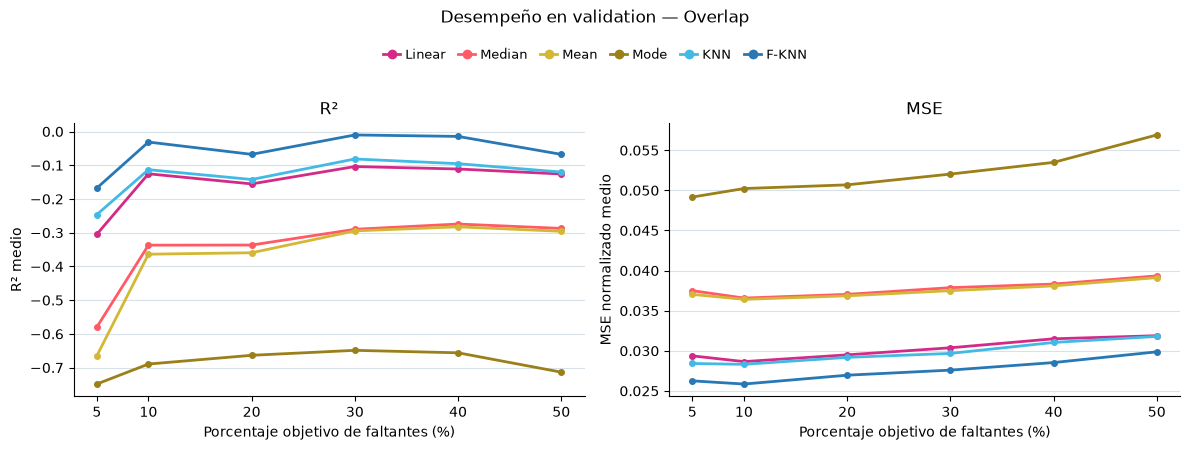

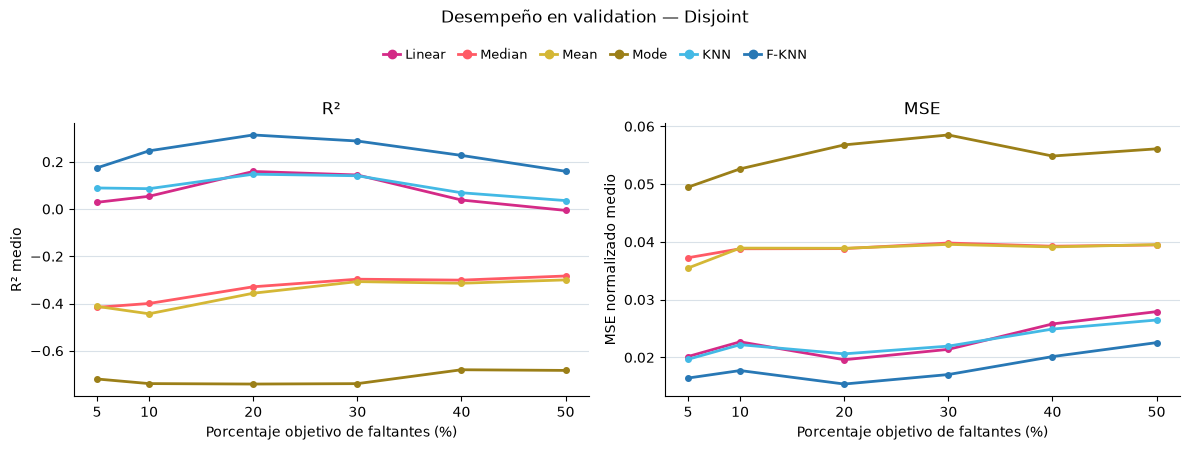

In [38]:
validation_performance_plot(50)

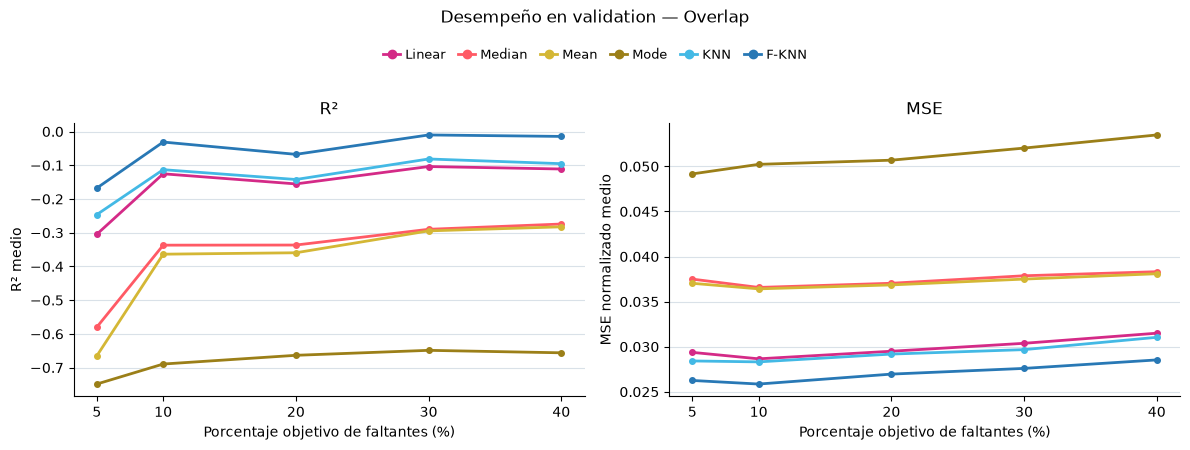

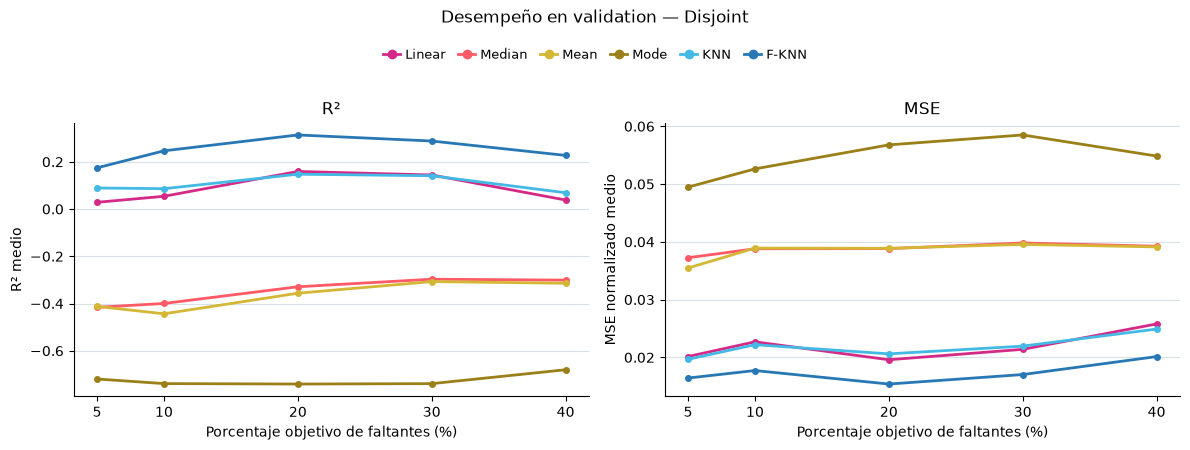

In [39]:
validation_performance_plot(40)

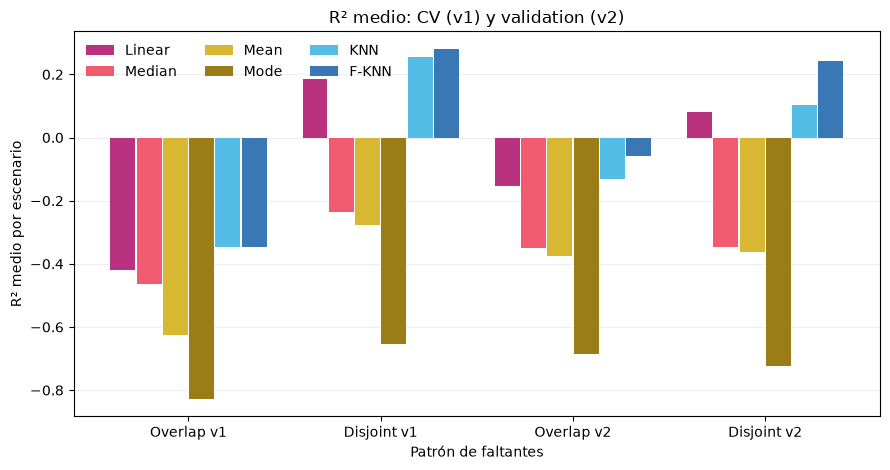

In [40]:
# KNN y F-KNN se comparan usando la configuración evaluada en validation.
metodo_knn = resultados_val_knn["metodo"].iloc[0]
metodo_fknn = resultados_val_fknn["metodo"].iloc[0]

mapas = [
    # Train (v1): promedio out-of-fold de CV
    (resultados_cv_baseline, "v1", {
        "Median": "Mediana",
        "Mean": "Media",
        "Mode": "Moda",
    }),
    (resultados_cv_linear, "v1", {"Linear": "LinearRegression"}),
    (resultados_cv_knn, "v1", {"KNN": metodo_knn}),
    (resultados_cv_fknn, "v1", {"F-KNN": metodo_fknn}),

    # Validation (v2): evaluacion 2019
    (resultados_val_baseline, "v2", {
        "Median": "Mediana",
        "Mean": "Media",
        "Mode": "Moda",
    }),
    (resultados_val_linear, "v2", {"Linear": "LinearRegression"}),
    (resultados_val_knn, "v2", {"KNN": metodo_knn}),
    (resultados_val_fknn, "v2", {"F-KNN": metodo_fknn}),
]

filas = []
for df, fase, equivalencias in mapas:
    for etiqueta, metodo in equivalencias.items():
        sub = df[(df["metodo"] == metodo)& (df["pct_objetivo"] <= 50)]

        for patron, datos_patron in sub.groupby("patron"):
            filas.append({
                "modelo": etiqueta,
                "categoria": f"{patron.capitalize()} {fase}",
                "R2": datos_patron["R2"].mean(),
            })

resumen_barras = pd.DataFrame(filas)

categorias = [
    "Overlap v1",
    "Disjoint v1",
    "Overlap v2",
    "Disjoint v2",
]
modelos = ["Linear", "Median", "Mean", "Mode", "KNN", "F-KNN"]

tabla_barras = (
    resumen_barras
    .pivot(index="categoria", columns="modelo", values="R2")
    .reindex(index=categorias, columns=modelos)
)

colores = {
    "Linear": "#B83280",
    "Median": "#F05B70",
    "Mean": "#D8B832",
    "Mode": "#9A7D16",
    "KNN": "#54BDE5",
    "F-KNN": "#3978B5",
}

fig, ax = plt.subplots(figsize=(9, 4.8))

x = np.arange(len(categorias))
modelos_presentes = [
    modelo for modelo in modelos
    if modelo in tabla_barras.columns and tabla_barras[modelo].notna().any()
]
ancho = 0.82 / len(modelos_presentes)

for i, modelo in enumerate(modelos_presentes):
    desplazamiento = (i - (len(modelos_presentes) - 1) / 2) * ancho
    ax.bar(
        x + desplazamiento,
        tabla_barras[modelo].to_numpy(),
        width=ancho * 0.95,
        color=colores[modelo],
        label=modelo,
    )

ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.set_ylabel("R² medio por escenario")
ax.set_xlabel("Patrón de faltantes")
ax.set_title("R² medio: CV (v1) y validation (v2)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper left")

fig.tight_layout()
plt.show()